# Clustering Algorithms Implementation & Performance Evaluation
This notebook demonstrates clustering techniques on a real-world dataset (Iris dataset):
1. **K-Means Clustering**
2. **Hierarchical / Agglomerative Clustering**
3. **DBSCAN (Density-Based Spatial Clustering of Applications with Noise)**

Evaluations are performed using **Silhouette Score**, **Davies-Bouldin Index**, **Calinski-Harabasz Index**, and 2D PCA visualizations.

In [1]:
# ==============================================================================
# SECTION 1: IMPORTS & DATA PREPARATION
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Load real-world Iris dataset
iris = load_iris()
X = iris.data
feature_names = iris.feature_names

# Standardize features for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dimensionality reduction for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Results dictionary
results = {}

def evaluate_clustering(name, labels, X_data):
    """Helper function to evaluate clustering performance."""
    # Exclude noise points (-1) if any (e.g., in DBSCAN) for metric computation
    unique_labels = set(labels)
    valid_mask = labels != -1 if -1 in unique_labels else np.ones(len(labels), dtype=bool)

    n_clusters = len(unique_labels - {-1})
    if n_clusters > 1:
        sil = silhouette_score(X_data[valid_mask], labels[valid_mask])
        db = davies_bouldin_score(X_data[valid_mask], labels[valid_mask])
        ch = calinski_harabasz_score(X_data[valid_mask], labels[valid_mask])
    else:
        sil, db, ch = np.nan, np.nan, np.nan

    results[name] = {
        'Clusters': n_clusters,
        'Silhouette Score': sil,
        'Davies-Bouldin Index': db,
        'Calinski-Harabasz Index': ch
    }

    print(f"--- {name} Performance ---")
    print(f"Estimated Clusters: {n_clusters}")
    print(f"Silhouette Score   : {sil:.4f} (Higher is better)")
    print(f"Davies-Bouldin Index: {db:.4f} (Lower is better)")
    print(f"Calinski-Harabasz  : {ch:.4f} (Higher is better)\n")

## K-Means Clustering

--- K-Means Performance ---
Estimated Clusters: 3
Silhouette Score   : 0.4599 (Higher is better)
Davies-Bouldin Index: 0.8336 (Lower is better)
Calinski-Harabasz  : 241.9044 (Higher is better)



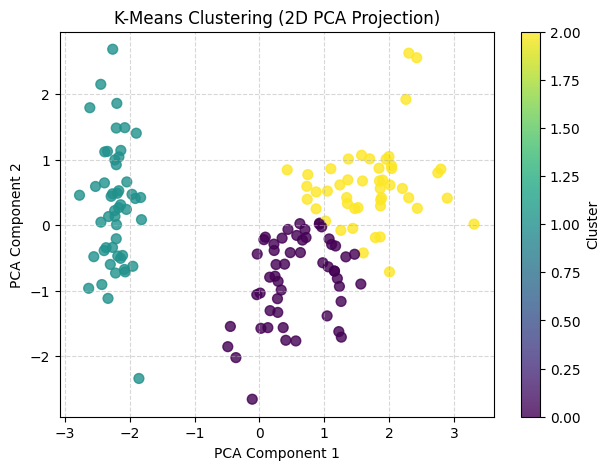

In [2]:
# ==============================================================================
# SECTION 2: K-MEANS CLUSTERING
# ==============================================================================
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

evaluate_clustering("K-Means", kmeans_labels, X_scaled)

# Visualization
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', s=50, alpha=0.8)
plt.title("K-Means Clustering (2D PCA Projection)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Agglomerative Hierarchical Clustering

--- Agglomerative Clustering Performance ---
Estimated Clusters: 3
Silhouette Score   : 0.4467 (Higher is better)
Davies-Bouldin Index: 0.8035 (Lower is better)
Calinski-Harabasz  : 222.7192 (Higher is better)



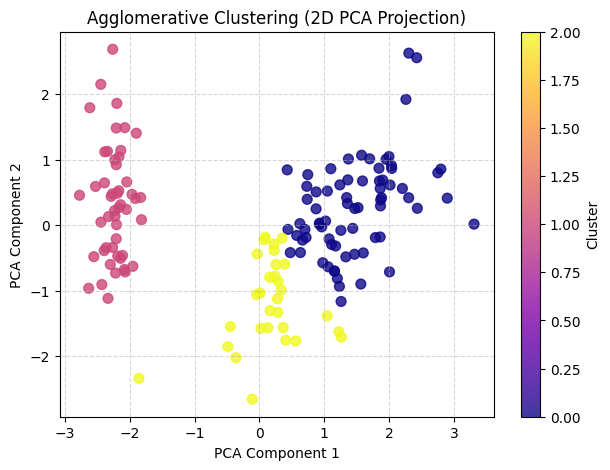

In [3]:
# ==============================================================================
# SECTION 3: AGGLOMERATIVE HIERARCHICAL CLUSTERING
# ==============================================================================
from sklearn.cluster import AgglomerativeClustering

agg_clustering = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg_clustering.fit_predict(X_scaled)

evaluate_clustering("Agglomerative Clustering", agg_labels, X_scaled)

# Visualization
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=agg_labels, cmap='plasma', s=50, alpha=0.8)
plt.title("Agglomerative Clustering (2D PCA Projection)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## DBSCAN (Density-Based Spatial Clustering)

--- DBSCAN Performance ---
Estimated Clusters: 2
Silhouette Score   : 0.6419 (Higher is better)
Davies-Bouldin Index: 0.5121 (Lower is better)
Calinski-Harabasz  : 330.9165 (Higher is better)



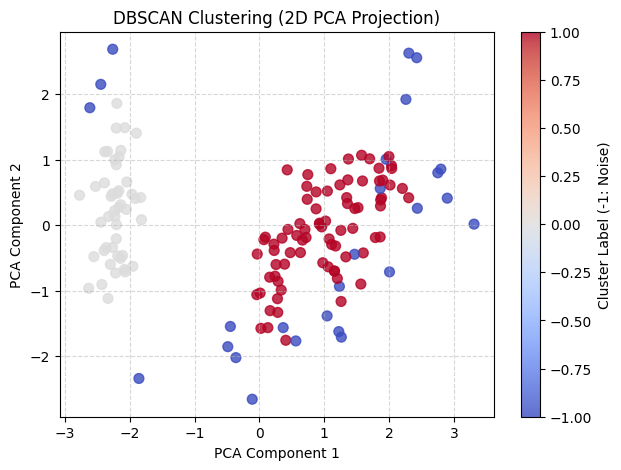

In [4]:
# ==============================================================================
# SECTION 4: DBSCAN CLUSTERING
# ==============================================================================
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.6, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

evaluate_clustering("DBSCAN", dbscan_labels, X_scaled)

# Visualization
plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='coolwarm', s=50, alpha=0.8)
plt.title("DBSCAN Clustering (2D PCA Projection)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(label='Cluster Label (-1: Noise)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Comparative Analysis Summary

                   CLUSTERING EVALUATION SUMMARY                      
                          Clusters  Silhouette Score  Davies-Bouldin Index  \
K-Means                        3.0            0.4599                0.8336   
Agglomerative Clustering       3.0            0.4467                0.8035   
DBSCAN                         2.0            0.6419                0.5121   

                          Calinski-Harabasz Index  
K-Means                                  241.9044  
Agglomerative Clustering                 222.7192  
DBSCAN                                   330.9165  



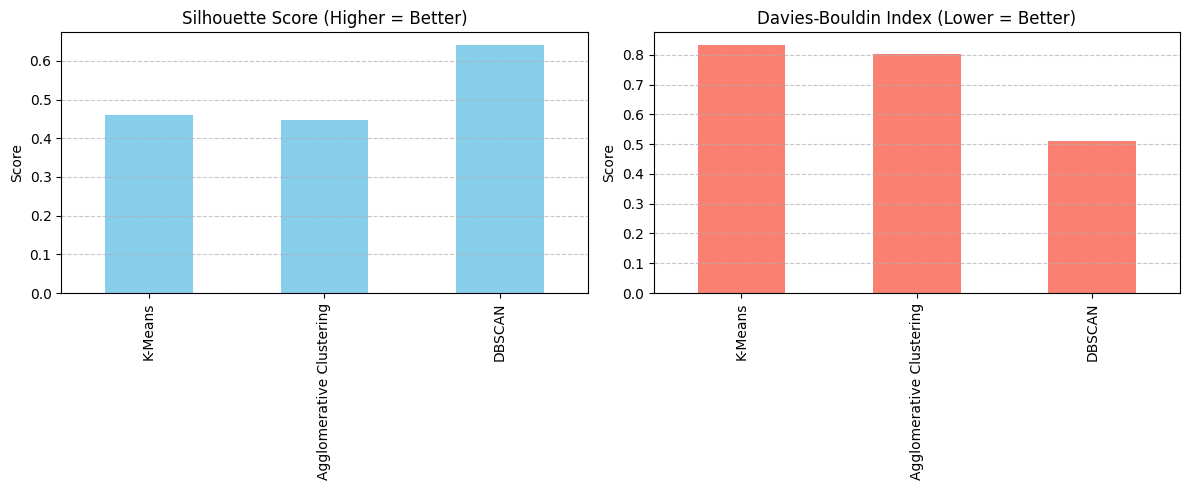

In [5]:
# ==============================================================================
# SECTION 5: COMPARATIVE ANALYSIS SUMMARY
# ==============================================================================
df_results = pd.DataFrame(results).T
print("=====================================================================")
print("                   CLUSTERING EVALUATION SUMMARY                      ")
print("=====================================================================")
print(df_results.round(4))
print("=====================================================================\n")

# Visualization of Silhouette & Davies-Bouldin Scores
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

df_results['Silhouette Score'].plot(kind='bar', ax=ax[0], color='skyblue')
ax[0].set_title('Silhouette Score (Higher = Better)')
ax[0].set_ylabel('Score')
ax[0].grid(axis='y', linestyle='--', alpha=0.7)

df_results['Davies-Bouldin Index'].plot(kind='bar', ax=ax[1], color='salmon')
ax[1].set_title('Davies-Bouldin Index (Lower = Better)')
ax[1].set_ylabel('Score')
ax[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()